In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Study hours
X = np.array([
    1, 2, 3, 4, 5,
    6, 7, 8, 9, 10,
    11, 12, 13, 14, 15
]).reshape(-1, 1)

# Exam scores
y = np.array([
    35, 40, 45, 50, 55,
    60, 65, 70, 74, 78,
    82, 85, 88, 92, 95
])

print("Study Hours:")
print(X.flatten())

print("\nExam Scores:")
print(y)

Study Hours:
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]

Exam Scores:
[35 40 45 50 55 60 65 70 74 78 82 85 88 92 95]


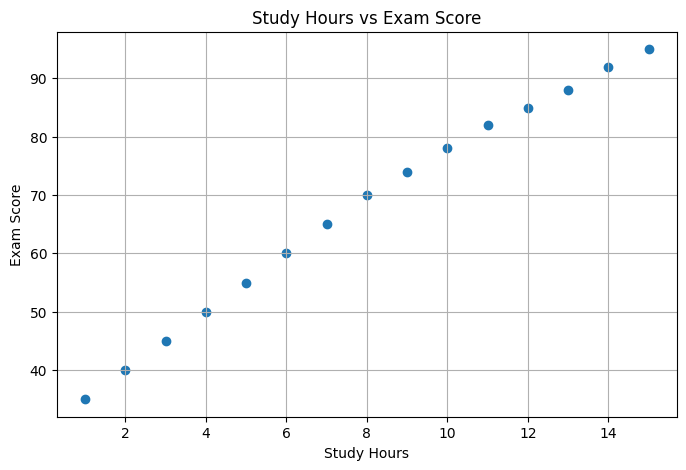

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(X, y)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.grid()
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 12
Testing samples: 3


In [ ]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

print("Slope:", linear_model.coef_[0])
print("Intercept:", linear_model.intercept_)

Slope: 4.238640853417621
Intercept: 33.73765310154089


In [ ]:
print("Actual Scores:")
print(y_test)

print("\nPredicted Scores:")
print(y_pred_linear)

Actual Scores:
[78 85 35]

Predicted Scores:
[76.12406164 84.60134334 37.97629395]


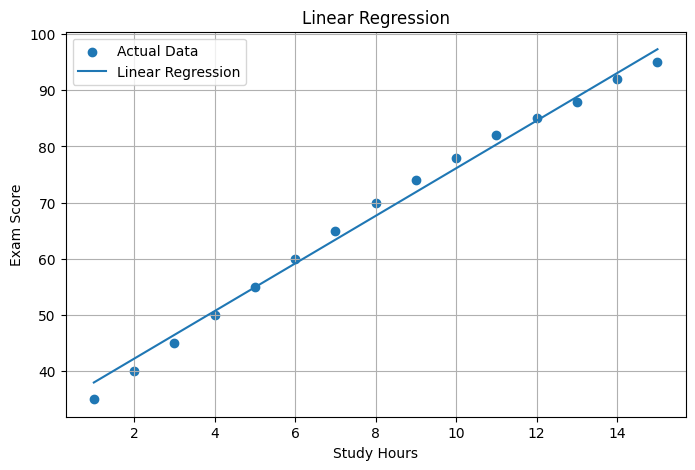

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual Data")

plt.plot(
    X,
    linear_model.predict(X),
    label="Linear Regression"
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Linear Regression")

plt.legend()
plt.grid()

plt.show()

In [ ]:
mse_linear = mean_squared_error(y_test, y_pred_linear)
mae_linear = mean_absolute_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("--------------------------------")
print("Mean Squared Error:", mse_linear)
print("Mean Absolute Error:", mae_linear)
print("R² Score:", r2_linear)

Linear Regression Performance
--------------------------------
Mean Squared Error: 4.178799194479427
Mean Absolute Error: 1.750296325563016
R² Score: 0.9914485691791007


In [ ]:
polynomial_model = Pipeline([
    ("polynomial_features", PolynomialFeatures(degree=2)),
    ("linear_regression", LinearRegression())
])

polynomial_model.fit(X_train, y_train)

y_pred_poly = polynomial_model.predict(X_test)

print("Polynomial Regression predictions:")
print(y_pred_poly)

Polynomial Regression predictions:
[77.78243359 85.25787848 33.80825685]


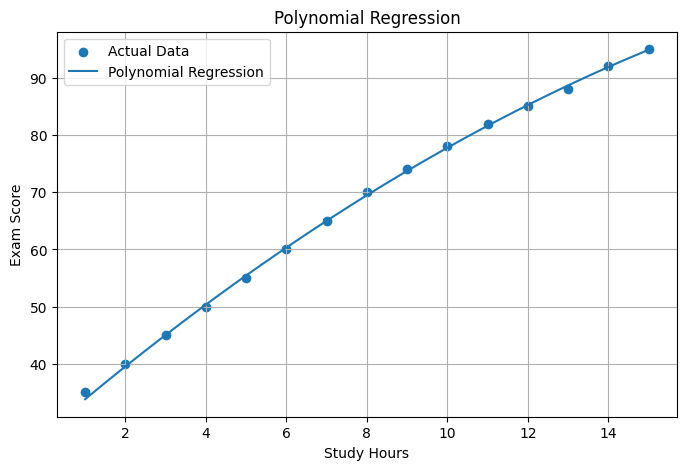

In [ ]:
X_curve = np.linspace(1, 15, 200).reshape(-1, 1)

y_curve = polynomial_model.predict(X_curve)

plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual Data")

plt.plot(
    X_curve,
    y_curve,
    label="Polynomial Regression"
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Polynomial Regression")

plt.legend()
plt.grid()

plt.show()

In [ ]:
mse_poly = mean_squared_error(y_test, y_pred_poly)
mae_poly = mean_absolute_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly)

print("Polynomial Regression Performance")
print("-----------------------------------")
print("Mean Squared Error:", mse_poly)
print("Mean Absolute Error:", mae_poly)
print("R² Score:", r2_poly)

Polynomial Regression Performance
-----------------------------------
Mean Squared Error: 0.5113627319501973
Mean Absolute Error: 0.5557293477001224
R² Score: 0.9989535551187922


In [ ]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)

print("Ridge Predictions:")
print(y_pred_ridge)

Ridge Predictions:
[76.08572552 84.52300433 38.1179709 ]


In [ ]:
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Performance")
print("-----------------------------")
print("MSE:", mse_ridge)
print("MAE:", mae_ridge)
print("R² Score:", r2_ridge)

Ridge Regression Performance
-----------------------------
MSE: 4.537904730211982
MAE: 1.836413684624458
R² Score: 0.9907137010977927


In [ ]:
lasso_model = Lasso(alpha=0.1)

lasso_model.fit(X_train, y_train)

y_pred_lasso = lasso_model.predict(X_test)

print("Lasso Predictions:")
print(y_pred_lasso)

Lasso Predictions:
[76.11315685 84.57905966 38.01659423]


In [ ]:
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression Performance")
print("-----------------------------")
print("MSE:", mse_lasso)
print("MAE:", mae_lasso)
print("R² Score:", r2_lasso)

Lasso Regression Performance
-----------------------------
MSE: 4.279069527064942
MAE: 1.7747925721058782
R² Score: 0.9912433775025956


In [ ]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MSE": [
        mse_linear,
        mse_poly,
        mse_ridge,
        mse_lasso
    ],
    "MAE": [
        mae_linear,
        mae_poly,
        mae_ridge,
        mae_lasso
    ],
    "R2 Score": [
        r2_linear,
        r2_poly,
        r2_ridge,
        r2_lasso
    ]
})

regression_results

,Model,MSE,MAE,R2 Score
0,Linear Regression,4.178799,1.750296,0.991449
1,Polynomial Regression,0.511363,0.555729,0.998954
2,Ridge Regression,4.537905,1.836414,0.990714
3,Lasso Regression,4.279070,1.774793,0.991243


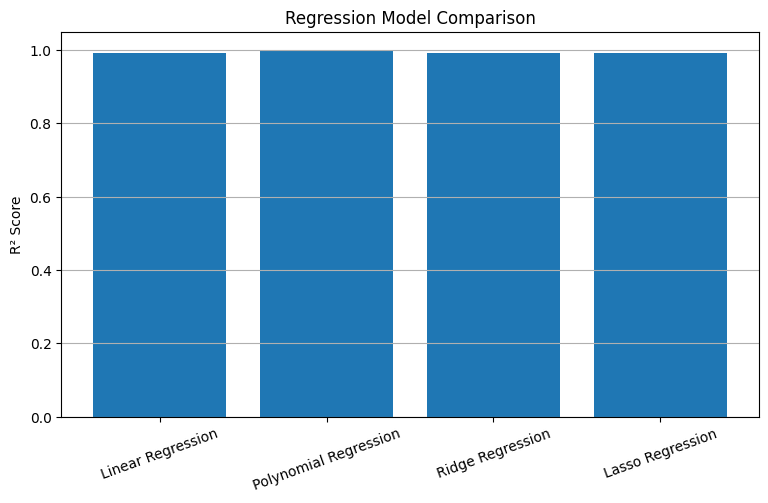

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    regression_results["Model"],
    regression_results["R2 Score"]
)

plt.ylabel("R² Score")
plt.title("Regression Model Comparison")

plt.xticks(rotation=20)
plt.grid(axis="y")

plt.show()

In [ ]:
X_class = np.array([
    [1, 50],
    [2, 55],
    [2, 60],
    [3, 58],
    [3, 65],
    [4, 62],
    [4, 70],
    [5, 68],
    [5, 75],
    [6, 72],
    [6, 80],
    [7, 78],
    [7, 85],
    [8, 82],
    [8, 90],
    [9, 88],
    [9, 92],
    [10, 95]
])

# 0 = Fail, 1 = Pass
y_class = np.array([
    0, 0, 0, 0, 0,
    0, 1, 1, 1, 1,
    1, 1, 1, 1, 1,
    1, 1, 1
])

print("Classification Dataset:")
print(X_class)

print("\nLabels:")
print(y_class)

Classification Dataset:
[[ 1 50]
 [ 2 55]
 [ 2 60]
 [ 3 58]
 [ 3 65]
 [ 4 62]
 [ 4 70]
 [ 5 68]
 [ 5 75]
 [ 6 72]
 [ 6 80]
 [ 7 78]
 [ 7 85]
 [ 8 82]
 [ 8 90]
 [ 9 88]
 [ 9 92]
 [10 95]]

Labels:
[0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1]


In [ ]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.25,
    random_state=42,
    stratify=y_class
)

print("Training samples:", len(X_train_c))
print("Testing samples:", len(X_test_c))

Training samples: 13
Testing samples: 5


In [ ]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.25,
    random_state=42,
    stratify=y_class
)

print("Training samples:", len(X_train_c))
print("Testing samples:", len(X_test_c))

Training samples: 13
Testing samples: 5


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)

print("Scaled Training Data:")
print(X_train_scaled)

Scaled Training Data:
[[ 0.92819752  0.65936686]
 [-0.53441675 -0.80589283]
 [ 1.65950465  1.61178566]
 [ 0.56254395  0.36631492]
 [-1.63137746 -1.68504864]
 [-0.16876319  0.14652597]
 [-1.26572389 -0.9524188 ]
 [ 0.92819752  1.24547074]
 [ 1.29385109  1.39199671]
 [-0.16876319 -0.36631492]
 [ 0.19689038 -0.07326298]
 [-1.26572389 -1.31873372]
 [-0.53441675 -0.21978895]]


In [ ]:
logistic_model = LogisticRegression()

logistic_model.fit(X_train_scaled, y_train_c)

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Predictions:")
print(y_pred_logistic)

Predictions:
[0 1 0 1 1]


In [ ]:
accuracy_logistic = accuracy_score(
    y_test_c,
    y_pred_logistic
)

print("Logistic Regression Accuracy:",
      accuracy_logistic)

Logistic Regression Accuracy: 1.0


In [ ]:
print(classification_report(
    y_test_c,
    y_pred_logistic
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [ ]:
cm = confusion_matrix(
    y_test_c,
    y_pred_logistic
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2 0]
 [0 3]]


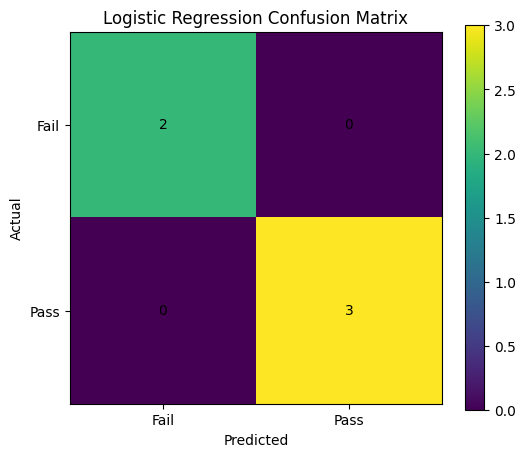

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

plt.xticks([0, 1], ["Fail", "Pass"])
plt.yticks([0, 1], ["Fail", "Pass"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=3)

knn_model.fit(
    X_train_scaled,
    y_train_c
)

y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN Predictions:")
print(y_pred_knn)

KNN Predictions:
[0 1 0 1 1]


In [ ]:
accuracy_knn = accuracy_score(
    y_test_c,
    y_pred_knn
)

print("KNN Accuracy:", accuracy_knn)

print("\nClassification Report:")
print(classification_report(
    y_test_c,
    y_pred_knn
))

KNN Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [ ]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_knn
    ]
})

classification_results

,Model,Accuracy
0,Logistic Regression,1.0
1,KNN,1.0


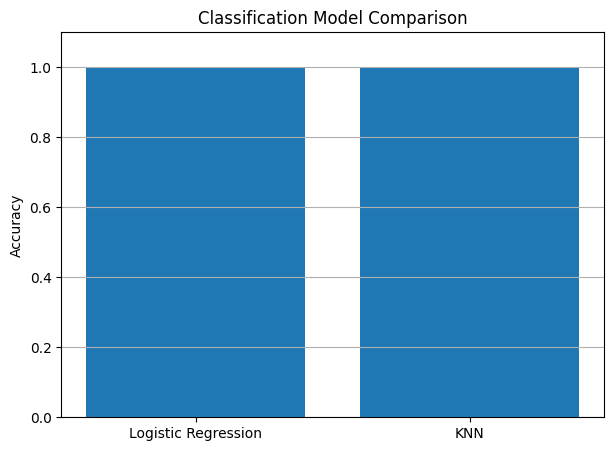

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    classification_results["Model"],
    classification_results["Accuracy"]
)

plt.ylabel("Accuracy")
plt.title("Classification Model Comparison")

plt.ylim(0, 1.1)
plt.grid(axis="y")

plt.show()

In [ ]:
print("=== Student Pass/Fail Prediction ===")

study_hours = float(input("Enter study hours: "))
attendance = float(input("Enter attendance percentage: "))

new_student = np.array([
    [study_hours, attendance]
])

new_student_scaled = scaler.transform(new_student)

logistic_prediction = logistic_model.predict(
    new_student_scaled
)

knn_prediction = knn_model.predict(
    new_student_scaled
)

if logistic_prediction[0] == 1:
    print("\nLogistic Regression: PASS")
else:
    print("\nLogistic Regression: FAIL")


if knn_prediction[0] == 1:
    print("KNN: PASS")
else:
    print("KNN: FAIL")

=== Student Pass/Fail Prediction ===
Enter study hours: 9
Enter attendance percentage: 88

Logistic Regression: PASS
KNN: PASS
